In [62]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [63]:
df=pd.read_csv("fifadata.csv")
print(df.head())

          short_name player_positions    value_eur  wage_eur  age  \
0           L. Messi               CF  100500000.0  550000.0   27   
1  Cristiano Ronaldo           LW, LM   79000000.0  375000.0   29   
2          A. Robben       RM, LM, RW   54500000.0  275000.0   30   
3    Z. Ibrahimovi€à               ST   52500000.0  275000.0   32   
4           M. Neuer               GK   63500000.0  300000.0   28   

             club_name nationality_name  
0         FC Barcelona        Argentina  
1       Real Madrid CF         Portugal  
2   FC Bayern MÌ?nchen      Netherlands  
3  Paris Saint-Germain           Sweden  
4   FC Bayern MÌ?nchen          Germany  


In [64]:
print(df.shape)

(169, 7)


In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169 entries, 0 to 168
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   short_name        169 non-null    object 
 1   player_positions  169 non-null    object 
 2   value_eur         163 non-null    float64
 3   wage_eur          164 non-null    float64
 4   age               169 non-null    int64  
 5   club_name         168 non-null    object 
 6   nationality_name  169 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 9.4+ KB


In [66]:
print(df.describe())

          value_eur       wage_eur         age
count  1.630000e+02     164.000000  169.000000
mean   2.028098e+07  150945.121951   27.869822
std    1.353299e+07   57925.724924    3.299654
min    1.300000e+06   50000.000000   21.000000
25%    1.250000e+07  120000.000000   26.000000
50%    1.600000e+07  140000.000000   28.000000
75%    2.300000e+07  170000.000000   30.000000
max    1.005000e+08  550000.000000   36.000000


In [67]:
numeric_columns = ['value_eur', 'wage_eur', 'age']
categorical_columns = ['short_name', 'player_positions', 'club_name', 'nationality_name']
print(numeric_columns)
print(categorical_columns)

['value_eur', 'wage_eur', 'age']
['short_name', 'player_positions', 'club_name', 'nationality_name']


This dataset contains football player information, including their names, positions, market values, wages, ages, clubs, and nationalities. I want to investigate whether older players tend to have higher market values and whether wages are related to market values. I also want to compare average player wages across different positions and identify which positions have the highest-paid players.

In [68]:
print(df.isna().sum())
df = df.dropna(subset=['value_eur', 'wage_eur', 'age', 'player_positions']).copy()

short_name          0
player_positions    0
value_eur           6
wage_eur            5
age                 0
club_name           1
nationality_name    0
dtype: int64


I removed rows missing these essential analysis values so comparisons and visualizations can use complete data. Other columns can retain missing values if they are not required for a particular analysis.

In [69]:
df['value_million'] = df['value_eur'].apply(lambda x: x / 1000000)

In [70]:
def classify_age(age):
    if age < 23:
        return 'Young'
    elif age < 30:
        return 'Prime'
    else:
        return 'Veteran'

df['age_group'] = df['age'].apply(classify_age)

In [71]:
print(df.head())

          short_name player_positions    value_eur  wage_eur  age  \
0           L. Messi               CF  100500000.0  550000.0   27   
1  Cristiano Ronaldo           LW, LM   79000000.0  375000.0   29   
2          A. Robben       RM, LM, RW   54500000.0  275000.0   30   
3    Z. Ibrahimovi€à               ST   52500000.0  275000.0   32   
4           M. Neuer               GK   63500000.0  300000.0   28   

             club_name nationality_name  value_million age_group  
0         FC Barcelona        Argentina          100.5     Prime  
1       Real Madrid CF         Portugal           79.0     Prime  
2   FC Bayern MÌ?nchen      Netherlands           54.5   Veteran  
3  Paris Saint-Germain           Sweden           52.5   Veteran  
4   FC Bayern MÌ?nchen          Germany           63.5     Prime  


In [72]:
df['value_category'] = np.where(df['value_eur'] >= 10000000, 'High Value', 'Other')

In [73]:
print(df.value_category)

0      High Value
1      High Value
2      High Value
3      High Value
4      High Value
          ...    
164    High Value
165    High Value
166    High Value
167    High Value
168         Other
Name: value_category, Length: 159, dtype: object


In [74]:
filtered_df = df[(df['age'] < 25) & (df['value_eur'] > 1000000)]
print(filtered_df.head())

     short_name player_positions   value_eur  wage_eur  age  \
11    E. Hazard           LM, RM  40500000.0  210000.0   23   
16      G. Bale           RM, RW  39000000.0  200000.0   24   
28   T. MÌ?ller  RM, CAM, ST, LM  39000000.0  200000.0   24   
29       Neymar               LW  31000000.0  210000.0   22   
30  T. Courtois               GK  27000000.0  170000.0   22   

             club_name nationality_name  value_million age_group  \
11             Chelsea          Belgium           40.5     Prime   
16      Real Madrid CF            Wales           39.0     Prime   
28  FC Bayern MÌ?nchen          Germany           39.0     Prime   
29        FC Barcelona           Brazil           31.0     Young   
30             Chelsea          Belgium           27.0     Young   

   value_category  
11     High Value  
16     High Value  
28     High Value  
29     High Value  
30     High Value  


In [75]:
df = df.sort_values(['player_positions', 'wage_eur'], ascending=[True, False])

In [76]:
print(df.player_positions)

130                CAM
158        CAM, CF, CM
44     CAM, CF, CM, RM
82             CAM, CM
50         CAM, CM, LM
            ...       
6               ST, CF
18              ST, CF
33              ST, CF
21         ST, CF, CAM
85              ST, RW
Name: player_positions, Length: 159, dtype: object


In [77]:
print(df.wage_eur)

130    130000.0
158     70000.0
44     150000.0
82     160000.0
50     160000.0
         ...   
6      300000.0
18     210000.0
33     160000.0
21     230000.0
85     120000.0
Name: wage_eur, Length: 159, dtype: float64


In [78]:
print(df.groupby('player_positions')['wage_eur'].mean())

player_positions
CAM                 130000.000000
CAM, CF, CM          70000.000000
CAM, CF, CM, RM     150000.000000
CAM, CM             160000.000000
CAM, CM, LM         160000.000000
CAM, CM, LM, CDM    120000.000000
CAM, CM, RM         230000.000000
CAM, LM             110000.000000
CAM, LM, CM         140000.000000
CAM, LM, RM         140000.000000
CAM, LW             190000.000000
CAM, RM             150000.000000
CAM, RW             190000.000000
CB                  151000.000000
CB, CDM             130000.000000
CB, RB              170000.000000
CB, RB, LB          140000.000000
CDM                 130000.000000
CDM, CM             131000.000000
CDM, RB, CM         190000.000000
CF                  550000.000000
CM                  123333.333333
CM, CAM             135000.000000
CM, CDM             162500.000000
CM, CDM, CAM        150000.000000
CM, LW              250000.000000
GK                  130384.615385
LB                  112500.000000
LB, CM, CDM, LM     120000.0000

In [79]:
grouped = df.groupby('player_positions')['wage_eur'].agg(['mean', 'min', 'max', 'count'])
print(grouped)

                           mean       min       max  count
player_positions                                          
CAM               130000.000000  130000.0  130000.0      1
CAM, CF, CM        70000.000000   70000.0   70000.0      1
CAM, CF, CM, RM   150000.000000  150000.0  150000.0      1
CAM, CM           160000.000000  160000.0  160000.0      1
CAM, CM, LM       160000.000000  160000.0  160000.0      1
CAM, CM, LM, CDM  120000.000000  120000.0  120000.0      1
CAM, CM, RM       230000.000000  230000.0  230000.0      1
CAM, LM           110000.000000  110000.0  110000.0      1
CAM, LM, CM       140000.000000  140000.0  140000.0      1
CAM, LM, RM       140000.000000  140000.0  140000.0      1
CAM, LW           190000.000000  190000.0  190000.0      1
CAM, RM           150000.000000  150000.0  150000.0      1
CAM, RW           190000.000000  190000.0  190000.0      1
CB                151000.000000   80000.0  220000.0     20
CB, CDM           130000.000000  130000.0  130000.0     

In [80]:
grouped = grouped.sort_values('mean', ascending=False)
print(grouped)

                           mean       min       max  count
player_positions                                          
CF                550000.000000  550000.0  550000.0      1
RM, LM, RW        275000.000000  275000.0  275000.0      1
LW, LM            252500.000000  130000.0  375000.0      2
CM, LW            250000.000000  250000.0  250000.0      1
CAM, CM, RM       230000.000000  230000.0  230000.0      1
ST, CF, CAM       230000.000000  230000.0  230000.0      1
ST, CF            223333.333333  160000.0  300000.0      3
LM, CAM           220000.000000  220000.0  220000.0      1
LW                210000.000000  210000.0  210000.0      1
RM, CAM, ST, LM   200000.000000  200000.0  200000.0      1
RM, RW            200000.000000  200000.0  200000.0      1
LM, RM            195000.000000  180000.0  210000.0      2
CAM, RW           190000.000000  190000.0  190000.0      1
CAM, LW           190000.000000  190000.0  190000.0      1
CDM, RB, CM       190000.000000  190000.0  190000.0     

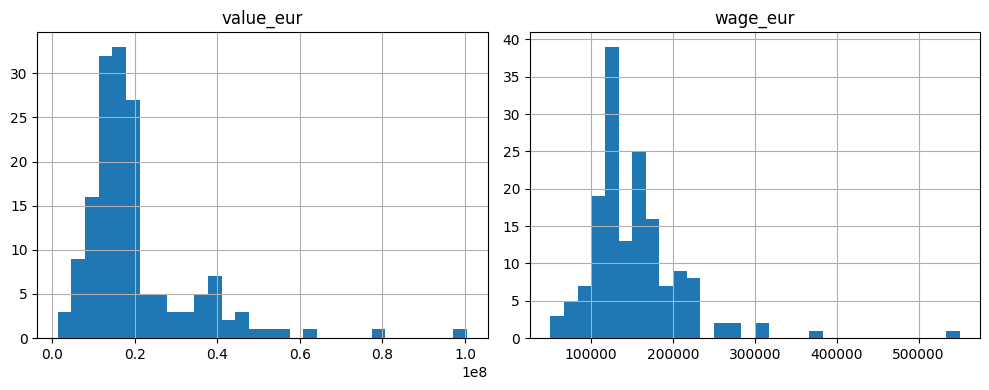

In [81]:
df[['value_eur', 'wage_eur']].hist(figsize=(10, 4), bins=30)
plt.tight_layout()
plt.show()

In [82]:
q1 = df['value_eur'].quantile(0.25)
q3 = df['value_eur'].quantile(0.75)
iqr = q3 - q1

outliers = df[df['value_eur'] > q3 + 1.5 * iqr]

print(outliers[['short_name', 'value_eur', 'age']].head())

       short_name    value_eur  age
26  Ì. Di MarÌ?a   45500000.0   26
24       M. ÌÐzil   44000000.0   25
31  J. RodrÌ?guez   35000000.0   22
25     M. Hummels   35500000.0   25
0        L. Messi  100500000.0   27


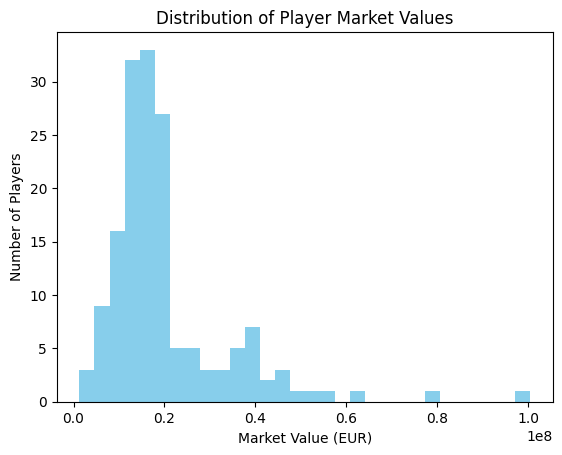

In [83]:
plt.hist(df['value_eur'], bins=30, color='skyblue')
plt.title('Distribution of Player Market Values')
plt.xlabel('Market Value (EUR)')
plt.ylabel('Number of Players')
plt.show()

Check whether market values are concentrated at the lower end or distributed more evenly. A long right tail indicates that a small number of players have much higher market values.

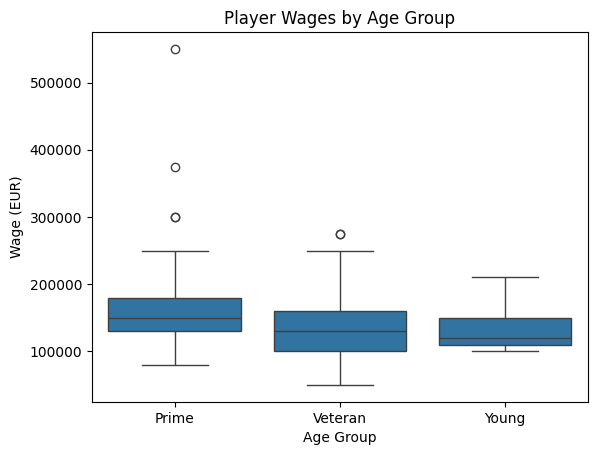

In [84]:
sns.boxplot(data=df, x='age_group', y='wage_eur')
plt.title('Player Wages by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Wage (EUR)')
plt.show()

Compare the median wages and spread across age groups. This helps reveal differences in wages, although age alone does not explain them.

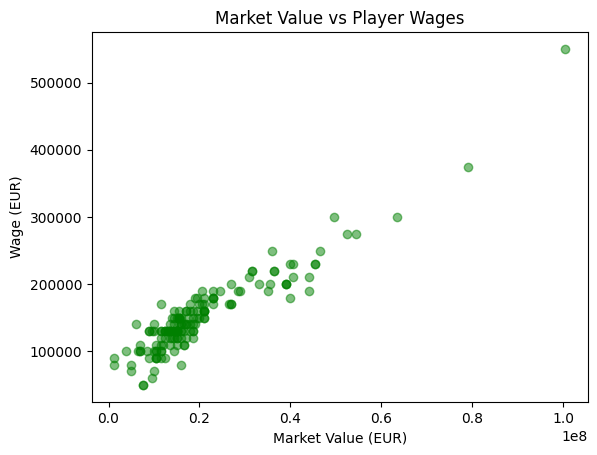

In [85]:
plt.scatter(df['value_eur'], df['wage_eur'], color='green', alpha=0.5)
plt.title('Market Value vs Player Wages')
plt.xlabel('Market Value (EUR)')
plt.ylabel('Wage (EUR)')
plt.show()

Look for an upward pattern, which would indicate that higher-valued players tend to receive higher wages. Outliers may represent players whose wages differ considerably from the general pattern.

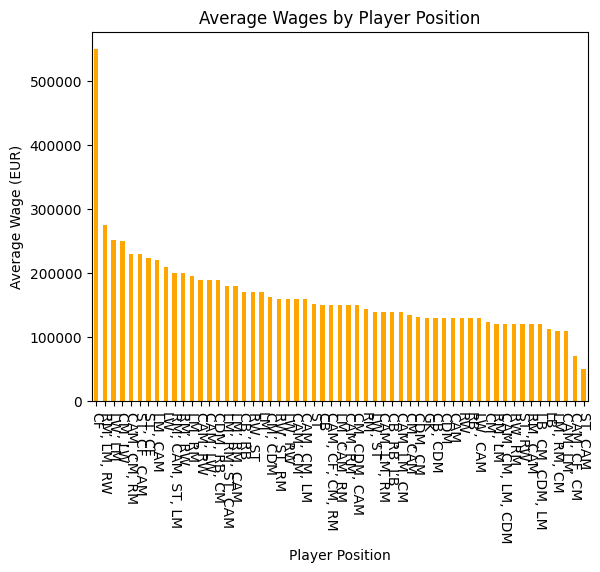

In [86]:
grouped['mean'].plot(kind='bar', color='orange')
plt.title('Average Wages by Player Position')
plt.xlabel('Player Position')
plt.ylabel('Average Wage (EUR)')
player_positions = grouped.index.tolist()
plt.xticks(range(len(player_positions)), player_positions, rotation=270)
plt.show()


Compare average wages across positions to identify differences in the dataset. Positions with few players may have averages that are especially sensitive to individual high earners like CF, i.e. L. Messi.

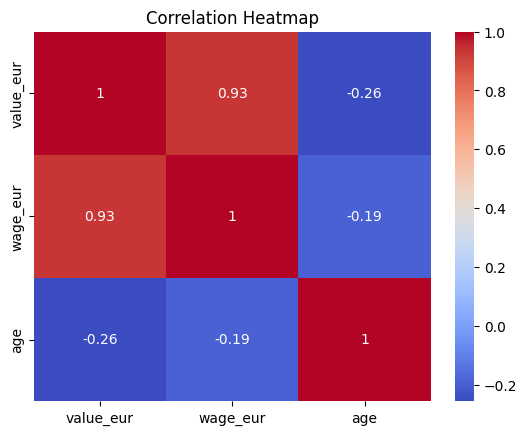

In [87]:
sns.heatmap(df[['value_eur', 'wage_eur', 'age']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Correlation coefficients show the strength and direction of linear relationships between age, market value, and wages. Correlation does not establish the process of one event or variable directly causing a change or result in another.

### Conclusions

**1. Age and market value:** The age-versus-value analysis helps establish whether player age is associated with market value. The conclusion should reflect the observed distribution and correlation rather than assuming that older players are more valuable.

**2. Wages and market value:** The scatter plot and correlation heatmap show whether wages and market values tend to increase together. Any observed association does not prove that market value directly determines wages but does have a connection, i.e. a 0.93 correlation.

**3. Wages by position:** The grouped statistics and boxplot allow comparisons of wages across player positions and age groups. Differences in group sizes and unusually high wages should be considered when interpreting the results. Specifically, the CF position, held by L. Messi alone, is considerd to be the most valuable position because ther is no other CF in our data of 170 rows.
